# Conditional number experiments (in progress)

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

In [ ]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from linear_transformer import generate_data
from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_data_condition_numbers,
    plot_loss_curves,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [ ]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

## Distribution shift: high-condition-number test data

Train layered and shared-weight looped transformers on standard Gaussian regression tasks with $d=5$ and $N=10$. Evaluate the same checkpoints on fixed, independent standard and transformed test batches. The transformed population covariance has condition number $1000$; individual context Gram matrices have varying condition numbers.

Training and test batch sizes, optimization, initialization, and checkpoint settings are shared with the first experiment. Training uses the repository's clipped `in_context_loss`; the plotted held-out loss is **unclipped** mean squared prediction error. Curves show the mean and standard deviation across training seeds; nonfinite losses are omitted and reported. First run the setup and problem-parameter cells above, then run this notebook in order.

In [24]:
import math

# Match the first experiment's seeds and architectures, using the requested sizes.
hc_seeds = [0, 1, 2]
hc_sizes = [1, 2, 5, 10]
hc_model_types = ['looped']

# Only the test distribution differs from the first experiment.
hc_cov_condition = 10000.0
hc_rotation_seed = 2000

if N != 10 or d != 5:
    raise ValueError('Run the first experiment\'s problem-parameter cell to set N=10 and d=5.')
print(f'High-condition experiment device: {device}')

High-condition experiment device: cuda


In [92]:
# Reuse the first experiment's training and evaluation settings.
hc_iterations = np.arange(0, max_iters, stride)
hc_fig_dir = os.path.join('figures', 'high_condition_test')
os.makedirs(hc_fig_dir, exist_ok=True)
hc_history_file = os.path.join(cur_dir, 'high_condition_N10_d5_histories.pth')
hc_results_file = os.path.join(cur_dir, 'high_condition_N10_d5_results.pth')

# Generate a fixed orthogonal basis by SVD, with a prescribed covariance spectrum.
torch.manual_seed(hc_rotation_seed)

svd_result = torch.linalg.svd(torch.randn(d, d, device=device))

hc_U = svd_result.U
hc_scales = torch.logspace(
    0, -0.5 * math.log10(hc_cov_condition), d, device=device,
)

hc_D = torch.diag(hc_scales)

print(f'Population covariance condition number: {torch.linalg.cond(hc_D).item() ** 2:.1f}')

Population covariance condition number: 10000.0


Updated todo list

For each normal covariate, `generate_data()` starts with $z \sim \mathcal N(0,I)$ and applies

$$
x = U D z.
$$

Here’s each component’s role:

1. **`hc_scales`** contains standard deviations ranging from $1$ down to $1/\sqrt{1000}$. These set the spread of the data in each principal direction.
2. **`hc_D`** places those scales on a diagonal: $D = \operatorname{diag}(\text{hc_scales})$.
3. **`hc_U`** rotates the scaled data. Because $U$ is orthogonal, it changes the directions but not the condition number.

The resulting **population covariance** is

$$
\Sigma = \operatorname{Cov}(x) = U D^2 U^\top.
$$

Its eigenvalues are the squared entries of `hc_scales`. Therefore, its condition number is

$$
\kappa(\Sigma)
= \frac{\text{largest eigenvalue}}{\text{smallest eigenvalue}}
= \frac{1^2}{(1/\sqrt{1000})^2}
= 1000.
$$

The fixed value applies to the **population covariance**. Each sampled context has only `N = 10` examples, so its empirical covariance will generally have a different condition number.

In [37]:
# Examine a reproducible batch from the high-condition test distribution.
torch.manual_seed(TEST_SEED)
hc_Z, _ = generate_data(normal_data_mode, N, d, B, U=hc_U, D=hc_D)
hc_data_conditions, hc_gram_conditions = compute_data_condition_numbers(hc_Z)
print(f'Median context X condition: {hc_data_conditions.median().item():.1f}')
print(f'Median context Gram condition: {hc_gram_conditions.median().item():.1f}')

NameError: name 'hc_U' is not defined

In [75]:
# Train on standard normal data using the existing training helper.
hc_hist_dict = run_experiment_suite(
    seeds=hc_seeds,
    n_layers_loops=hc_sizes,
    model_types=hc_model_types,
    filename=hc_history_file,
    context_lengths=[N],
)

Run 1/4: seed=0, count=1, type=looped, N=10
iter 0 | Loss: 4.782515525817871 | time: 0.0069239139556884766 | gradnorm: 3.1331946849823
iter 1 | Loss: 4.460882663726807 | time: 0.005681753158569336 | gradnorm: 3.160719156265259
iter 2 | Loss: 4.659054756164551 | time: 0.006200075149536133 | gradnorm: 3.2489049434661865
iter 3 | Loss: 4.460082054138184 | time: 0.005029439926147461 | gradnorm: 3.143481969833374
iter 4 | Loss: 4.543564319610596 | time: 0.004951953887939453 | gradnorm: 3.2081918716430664
iter 100 | Loss: 3.836466073989868 | time: 0.002681732177734375 | gradnorm: 3.024074077606201
iter 200 | Loss: 3.3473775386810303 | time: 0.0026710033416748047 | gradnorm: 2.7464020252227783
iter 300 | Loss: 2.8352458477020264 | time: 0.0026853084564208984 | gradnorm: 2.3970413208007812
iter 400 | Loss: 2.3862922191619873 | time: 0.0027616024017333984 | gradnorm: 1.8073077201843262
iter 500 | Loss: 2.0302138328552246 | time: 0.002690553665161133 | gradnorm: 1.1721309423446655
iter 600 | Los

In [ ]:
# Compare both distributions using the first experiment's fixed test seed and batch size.
hc_standard_loss = compute_loss_dict(
    hc_hist_dict, test_seed=TEST_SEED
)
hc_shifted_loss = compute_loss_dict(
    hc_hist_dict, U=hc_U, D=hc_D, test_seed=TEST_SEED
)

# Verify the actual condition numbers of the held-out context matrices.
torch.manual_seed(TEST_SEED)
hc_Z, _ = generate_data(normal_data_mode, N, d, B, U=hc_U, D=hc_D)
hc_data_conditions, hc_gram_conditions = compute_data_condition_numbers(hc_Z)
print(f'Median empirical context X condition: {hc_data_conditions.median().item():.1f}')
print(f'Median empirical context Gram condition: {hc_gram_conditions.median().item():.1f}')
for name, losses in [('standard', hc_standard_loss), ('shifted', hc_shifted_loss)]:
    n_nonfinite = sum((~torch.isfinite(values)).sum().item() for values in losses.values())
    print(f'{name} test: {n_nonfinite} missing or nonfinite checkpoint losses')

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head, 'mode': normal_data_mode,
        'shape_k': 0.1, 'alg': alg, 'lr': lr, 'clip_r': clip_r,
        'var': var, 'max_iters': max_iters, 'hist_stride': hist_stride,
        'stride': stride, 'seeds': hc_seeds, 'sizes': hc_sizes,
        'model_types': hc_model_types, 'test_seed': TEST_SEED,
        'cov_condition': hc_cov_condition, 'rotation_seed': hc_rotation_seed,
    },
    'history_file': hc_history_file,
    'standard_loss': hc_standard_loss,
    'shifted_loss': hc_shifted_loss,
    'U': hc_U.cpu(),
    'D': hc_D.cpu(),
    'iterations': hc_iterations,
    'context_gram_conditions': hc_gram_conditions.cpu(),
}, hc_results_file)
print(f'Saved results to {hc_results_file}')

Median empirical context Gram condition: 18412.9
standard test: 0 missing or nonfinite checkpoint losses
shifted test: 0 missing or nonfinite checkpoint losses
Saved results to log/high_condition_N10_d5_results.pth


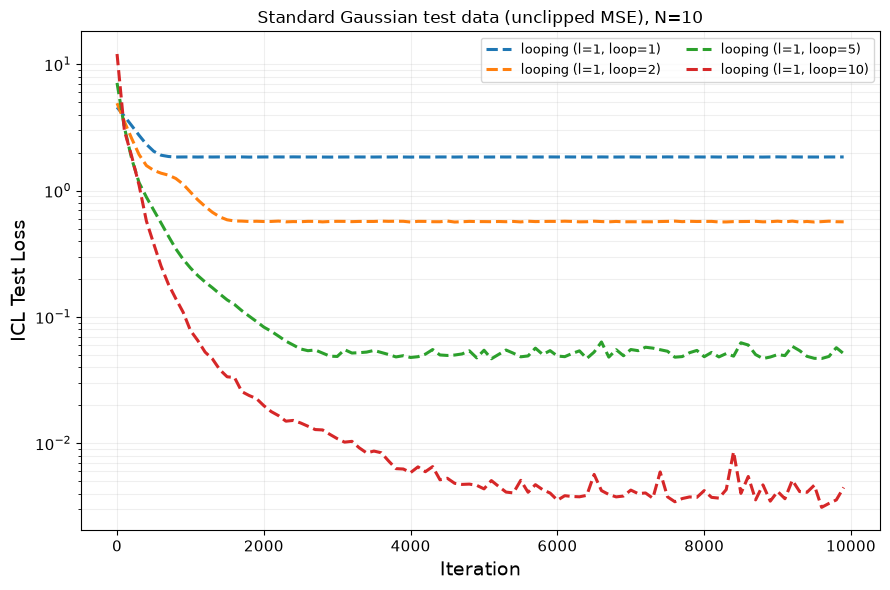

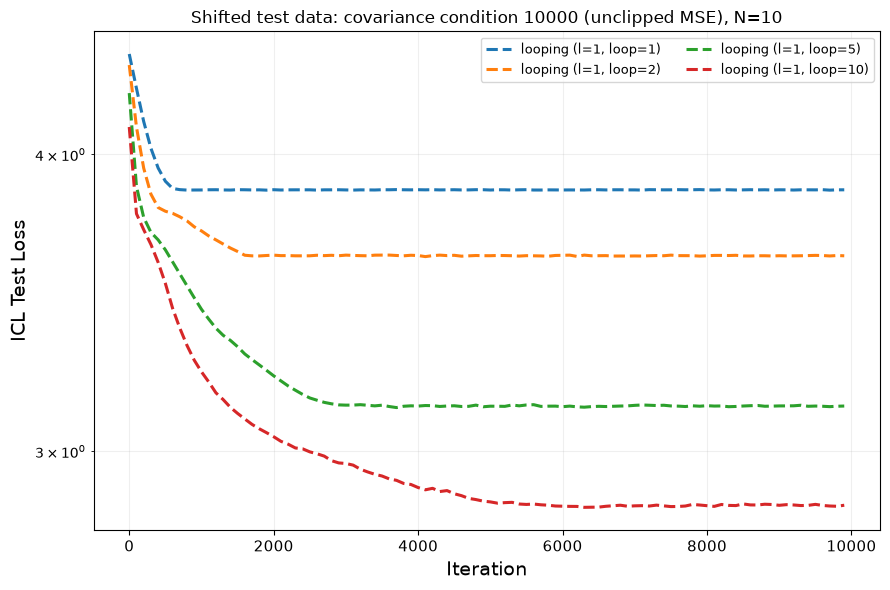

In [77]:
# Plot both test distributions with the existing plotting helper.
plot_loss_curves(
    hc_standard_loss, hc_sizes, hc_model_types, hc_iterations,
    fig_dir=hc_fig_dir, filename='standard_test_loss.pdf',
    title='Standard Gaussian test data (unclipped MSE)',
)
plot_loss_curves(
    hc_shifted_loss, hc_sizes, hc_model_types, hc_iterations,
    fig_dir=hc_fig_dir, filename='high_condition_test_loss.pdf',
    title=f'Shifted test data: covariance condition {hc_cov_condition:.0f} (unclipped MSE)',
)